In [3]:
import pandas as pd
import numpy as np

# Load dataset
df = pd.read_csv("Fruit Prices 2022.csv")

# Display basic information
print("Shape:", df.shape)
print("\nColumn names:")
print(df.columns)

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nNumber of duplicate rows:", df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates()

# Remove leading/trailing spaces from column names
df.columns = df.columns.str.strip()

# Remove leading/trailing spaces from categorical/text columns
categorical_columns = df.select_dtypes(include="object").columns

for col in categorical_columns:
    df[col] = df[col].str.strip()

# Check data types
print("\nData types:")
print(df.dtypes)

# Convert numerical columns to numeric
numerical_columns = [
    "RetailPrice",
    "Yield",
    "CupEquivalentSize",
    "CupEquivalentPrice"
]

for col in numerical_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Check missing values created during conversion
print("\nMissing values after conversion:")
print(df.isnull().sum())

# Remove rows containing missing values
df = df.dropna()

# Check for impossible/negative values
print("\nNegative values:")
print((df[numerical_columns] < 0).sum())

# Remove rows with negative numerical values
for col in numerical_columns:
    df = df[df[col] >= 0]

# Reset index
df = df.reset_index(drop=True)

# Final dataset information
print("\nFinal dataset shape:", df.shape)
print("\nFinal missing values:")
print(df.isnull().sum())

print("\nFirst 5 rows:")
print(df.head())


Shape: (62, 8)

Column names:
Index(['Fruit', 'Form', 'RetailPrice', 'RetailPriceUnit', 'Yield',
       'CupEquivalentSize', 'CupEquivalentUnit', 'CupEquivalentPrice'],
      dtype='object')

Missing values:
Fruit                 0
Form                  0
RetailPrice           0
RetailPriceUnit       0
Yield                 0
CupEquivalentSize     0
CupEquivalentUnit     0
CupEquivalentPrice    0
dtype: int64

Number of duplicate rows: 0

Data types:
Fruit                  object
Form                   object
RetailPrice           float64
RetailPriceUnit        object
Yield                 float64
CupEquivalentSize     float64
CupEquivalentUnit      object
CupEquivalentPrice    float64
dtype: object

Missing values after conversion:
Fruit                 0
Form                  0
RetailPrice           0
RetailPriceUnit       0
Yield                 0
CupEquivalentSize     0
CupEquivalentUnit     0
CupEquivalentPrice    0
dtype: int64

Negative values:
RetailPrice           0
Yield     

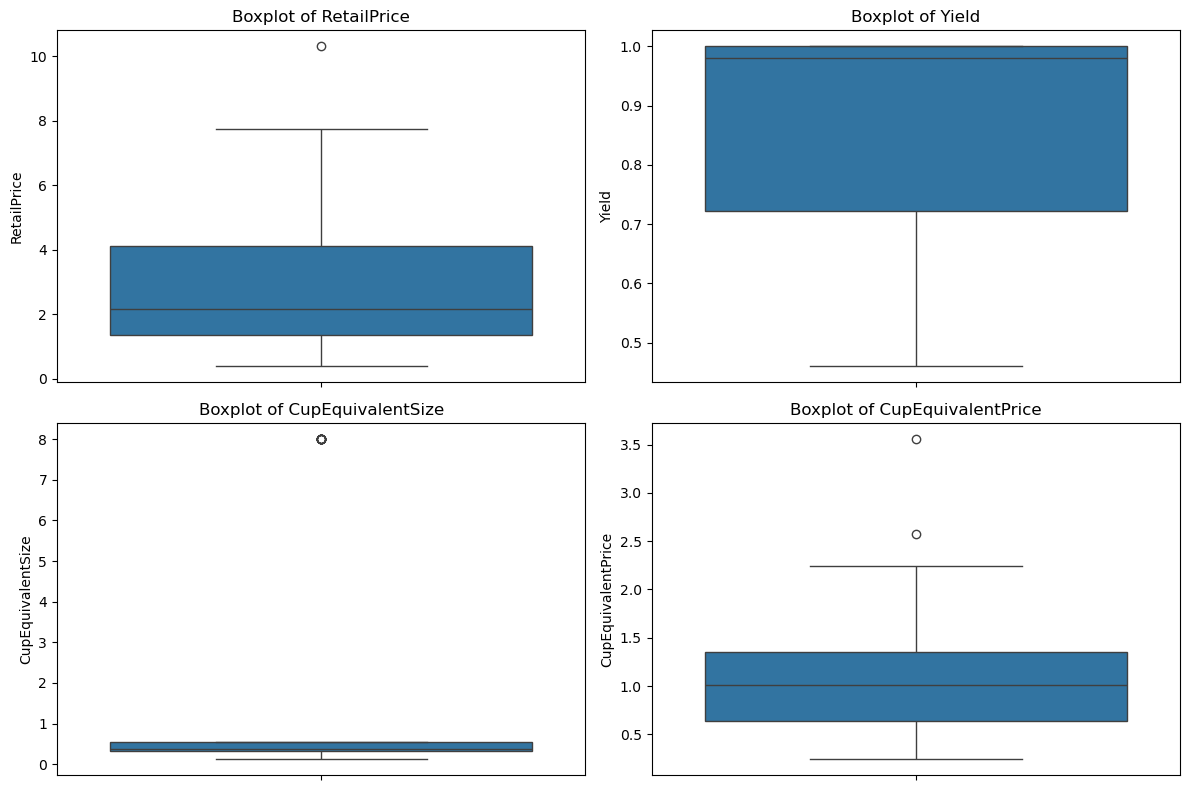

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 8))

for i, col in enumerate(numerical_columns, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(y=df[col])
    plt.title(f"Boxplot of {col}")

plt.tight_layout()
plt.show()


In [5]:
df.describe()


,RetailPrice,Yield,CupEquivalentSize,CupEquivalentPrice
count,62.000000,62.000000,62.000000,62.000000
mean,2.994571,0.876129,1.704984,1.065056
std,2.269393,0.174979,2.949262,0.578325
min,0.382000,0.460000,0.123200,0.242900
25%,1.364225,0.722500,0.322450,0.639300
50%,2.159250,0.980000,0.363800,1.008250
75%,4.116525,1.000000,0.540100,1.353475
max,10.303500,1.000000,8.000000,3.555800


In [6]:
df.to_csv("Fruit_Prices_2022_Cleaned.csv", index=False)

print("Cleaned dataset saved successfully.")


Cleaned dataset saved successfully.
